In [1]:
# import some helpful python packages 
import numpy as np
from astropy.table import Table
from astropy.convolution import convolve, Gaussian1DKernel
import matplotlib 
import matplotlib.pyplot as plt

# DESI targeting masks 
from desitarget import targetmask            # For Main survey
from desitarget.sv1 import sv1_targetmask    # For SV1
from desitarget.sv2 import sv2_targetmask    # For SV2
from desitarget.sv3 import sv3_targetmask    # For SV3

# DataLab related modules
from sparcl.client import SparclClient
from dl import queryClient as qc, authClient as ac
from getpass import getpass

In [2]:
ac.whoAmI()

'anonymous'

In [3]:
# Making the matplotlib plots look nicer

settings = {
    'font.size':16,
    'axes.linewidth':2.0,
    'xtick.major.size':6.0,
    'xtick.minor.size':4.0,
    'xtick.major.width':2.0,
    'xtick.minor.width':1.5,
    'xtick.direction':'in', 
    'xtick.minor.visible':True,
    'xtick.top':True,
    'ytick.major.size':6.0,
    'ytick.minor.size':4.0,
    'ytick.major.width':2.0,
    'ytick.minor.width':1.5,
    'ytick.direction':'in', 
    'ytick.minor.visible':True,
    'ytick.right':True
}

plt.rcParams.update(**settings)

In [4]:
# Load SPARCLClient
client = SparclClient()

announcement=Data set deprecation notice: on November 19, 2025 the SDSS/BOSS DR16 data sets were deprecated. Please use the new SDSS/BOSS DR17 data sets instead.


In [51]:
#try selecting on target ID 
tid=39628016040543831
inc = ['specid', 'redshift', 'flux', 'wavelength', 'spectype', 'specprimary', 'survey', 'program', 'targetid', 'redshift_warning']
res = client.retrieve_by_specid(specid_list = [tid],
                                include = inc,
                                dataset_list = ['DESI-DR1'])

In [52]:
res

Retrieved Results: 1 records

In [53]:
records = res.records

In [54]:
# Select the primary spectrum
spec_primary = np.array([records[jj].specprimary for jj in range(len(records))])

primary_ii = np.where(spec_primary == True)[0][0]

In [55]:
lam_primary = records[primary_ii].wavelength
flam_primary = records[primary_ii].flux

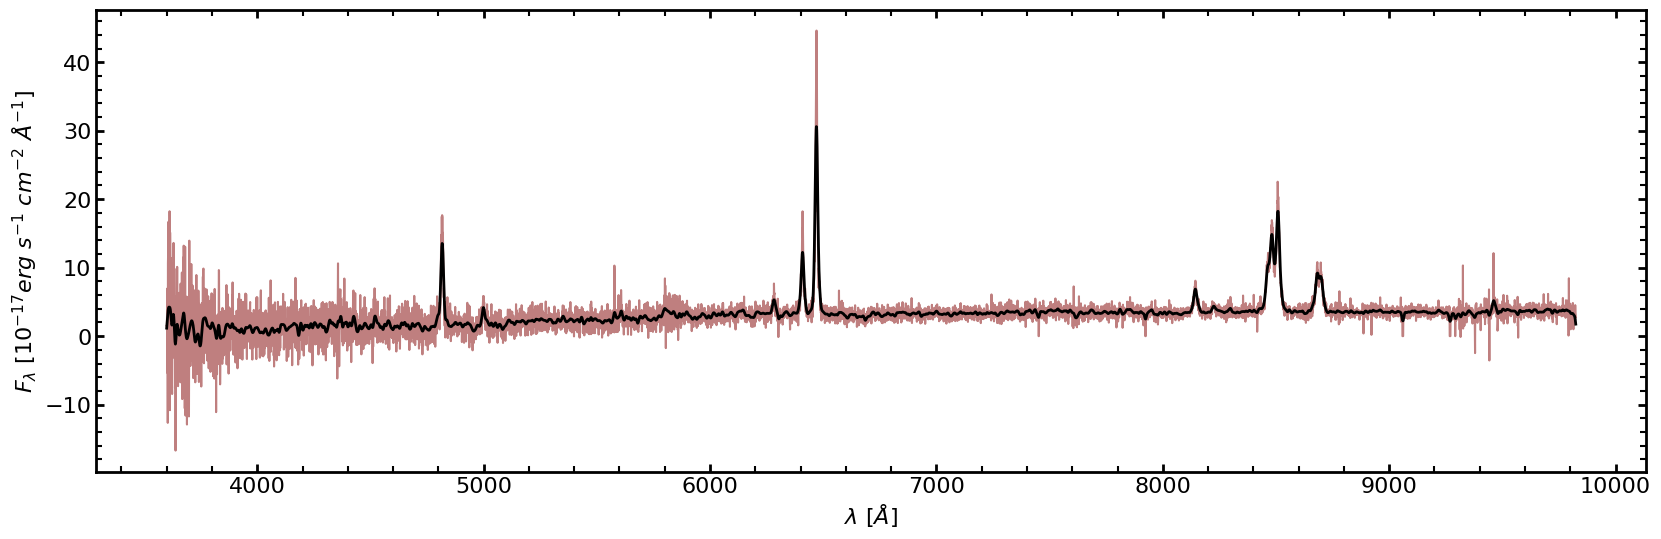

In [56]:
plt.figure(figsize = (20, 6))

# Plot the original spectrum in maroon color
plt.plot(lam_primary, flam_primary, color = 'maroon', alpha = 0.5)
# Over-plotting smoothed spectra in black 
plt.plot(lam_primary, convolve(flam_primary, Gaussian1DKernel(5)), color = 'k', lw = 2.0)
plt.xlabel(r'$\lambda$ [$\AA$]')
plt.ylabel(r'$F_{\lambda}$ [$10^{-17} erg\ s^{-1}\ cm^{-2}\ \AA^{-1}$]')
plt.show()

In [44]:
print(len(lam_primary))

7781


In [12]:
f=open('J125148.92+520026.9_desispec.csv','w')

In [13]:
f.write('Lambda,FLambda17 \n')

18

In [14]:
for i in range(len(lam_primary)):
    wstring=str(lam_primary[i])+','+str(flam_primary[i])+'\n'
    f.write(wstring)
f.close()